In [1]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import contextily as cx

from utilities import add_north_arrow, add_scalebar, save_mpl_fig

SAVEPATH = "../results/figures/supplementary/"

import warnings

warnings.filterwarnings("ignore")

## Regions

In [2]:
FP_REGION_SHP2014 = os.path.join(
    "zip://",
    "..",
    "build",
    "raw-data",
    "master-plan-2014-region-boundary-no-sea",
    "master-plan-2014-region-boundary-no-sea-shp.zip",
)
FP_SUBZONE_SHP2014 = os.path.join(
    "zip://",
    "..",
    "build",
    "raw-data",
    "master-plan-2014-subzone-boundary-no-sea",
    "master-plan-2014-subzone-boundary-no-sea-shp.zip",
)
FP_ZONE_SHP2014 = os.path.join(
    "zip://",
    "..",
    "build",
    "raw-data",
    "master-plan-2014-planning-area-boundary-no-sea",
    "master-plan-2014-planning-area-boundary-no-sea-shp.zip",
)


regions2014 = gpd.read_file(FP_REGION_SHP2014).to_crs("EPSG:4326")
zones = gpd.read_file(FP_ZONE_SHP2014).to_crs("EPSG:4326")
subzones = gpd.read_file(FP_SUBZONE_SHP2014).to_crs("EPSG:4326")

EDGECOLOR = "maroon"
LINEWIDTH = 3
MAPPROVIDER = cx.providers.CartoDB.PositronNoLabels
BASEMAP_OPTS = dict(crs=regions2014.crs, source=MAPPROVIDER, attribution="", zorder=0)

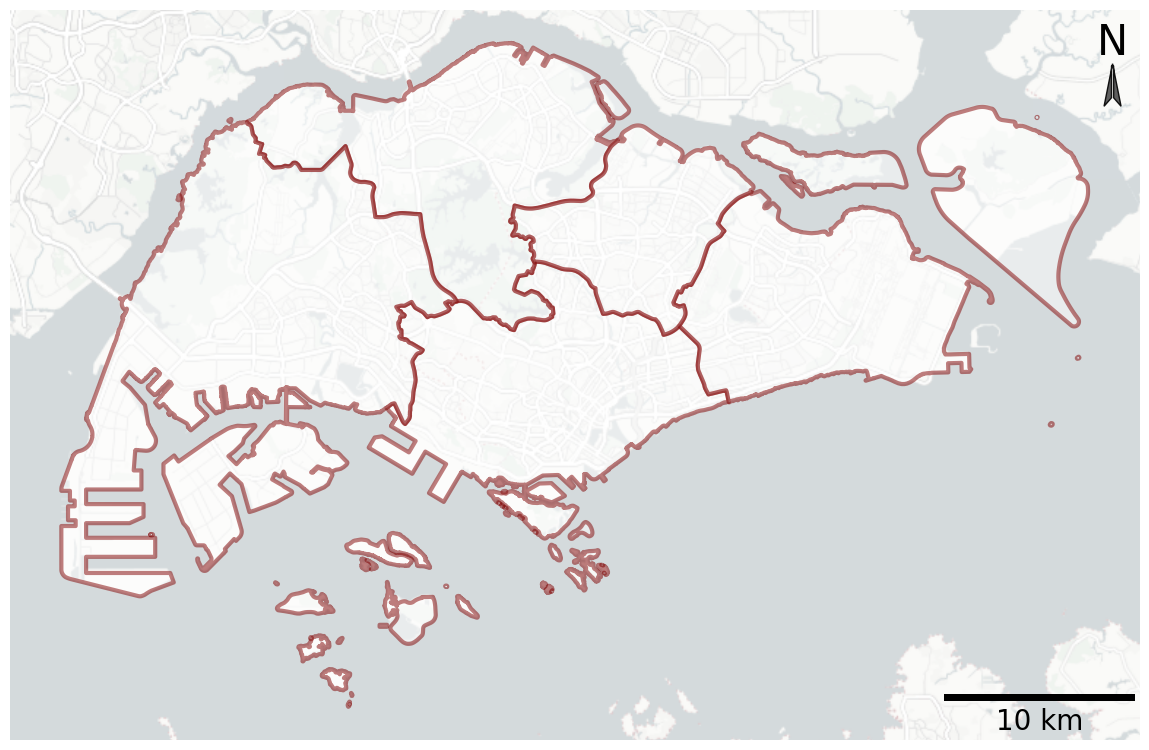

In [3]:
_, ax = plt.subplots(figsize=(12, 12))

regions2014.plot(
    color="white",
    edgecolor=EDGECOLOR,
    linewidth=LINEWIDTH,
    alpha=0.5,
    rasterized=True,
    ax=ax,
    zorder=1,
)

cx.add_basemap(**BASEMAP_OPTS, ax=ax)
add_north_arrow(ax=ax, x=104.1, y=1.46, fontsize=30)
add_scalebar(ax=ax, fontsize=20)
plt.tight_layout()
plt.margins(0, 0)
plt.axis("off")

save_mpl_fig(os.path.join(SAVEPATH, "borders-region"))

## Planning areas

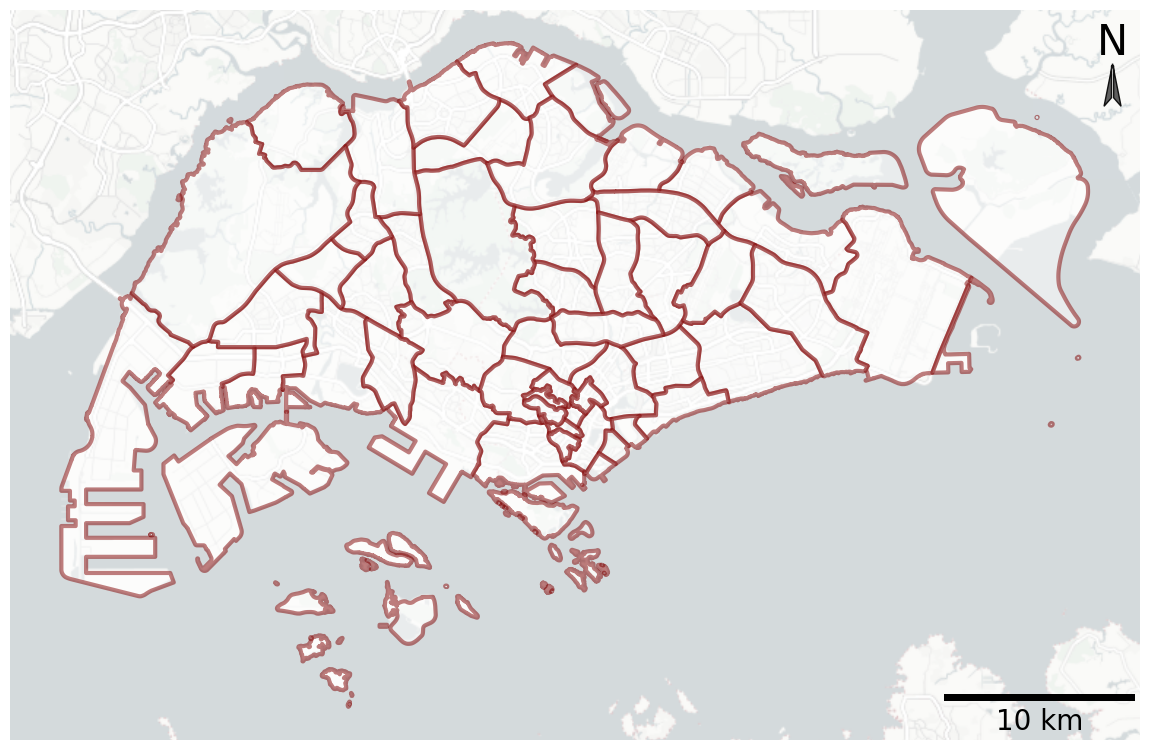

In [4]:
_, ax = plt.subplots(figsize=(12, 12))

zones.plot(
    color="white",
    edgecolor=EDGECOLOR,
    linewidth=LINEWIDTH,
    alpha=0.5,
    rasterized=True,
    ax=ax,
    zorder=1,
)

cx.add_basemap(**BASEMAP_OPTS, ax=ax)
add_north_arrow(ax=ax, x=104.1, y=1.46, fontsize=30)
add_scalebar(ax=ax, fontsize=20)
plt.tight_layout()
plt.margins(0, 0)
plt.axis("off")

save_mpl_fig(os.path.join(SAVEPATH, "borders-zones"))

## Subzones

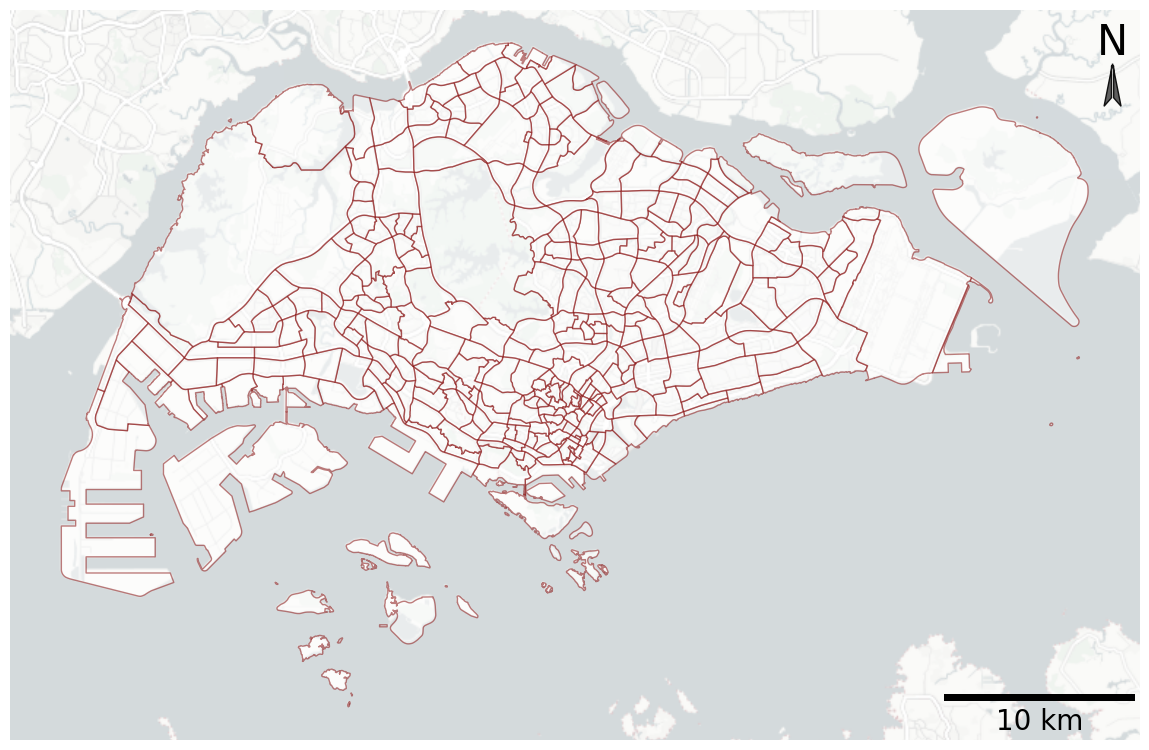

In [5]:
_, ax = plt.subplots(figsize=(12, 12))

subzones.plot(
    color="white",
    edgecolor=EDGECOLOR,
    linewidth=1,
    alpha=0.5,
    rasterized=True,
    ax=ax,
    zorder=1,
)

cx.add_basemap(**BASEMAP_OPTS, ax=ax)
add_north_arrow(ax=ax, x=104.1, y=1.46, fontsize=30)
add_scalebar(ax=ax, fontsize=20)
plt.tight_layout()
plt.margins(0, 0)
plt.axis("off")

save_mpl_fig(os.path.join(SAVEPATH, "borders-subzones"))

## Neighborhoods

In [6]:
FP_HTYPE = os.path.join("..", "build", "intermediate-output", "htype.csv")

# Read in URA2014 version
subzones2014 = (
    gpd.read_file(FP_SUBZONE_SHP2014)
    .rename(columns={"SUBZONE_N": "subzone"})
    .assign(subzone=lambda df: df["subzone"].str.lower())
    .assign(centroid=lambda df: df["geometry"].centroid)
    .to_crs("EPSG:4326")
)

htype = (
    pd.read_csv(FP_HTYPE, usecols=["area", "resident_count", "rm12", "private"])
    .rename(columns={"area": "subzone"})
    .assign(resident_count=lambda df: df["resident_count"].replace(0, np.nan))
)

htype = subzones2014[["subzone", "geometry", "PLN_AREA_N", "REGION_C"]].merge(
    htype, how="left", on="subzone", validate="1:1"
)
htype.head()

,subzone,geometry,PLN_AREA_N,REGION_C,resident_count,private,rm12
0,people's park,"POLYGON ((103.84319 1.28433, 103.84335 1.2842,...",OUTRAM,CR,310.0,100.000000,0.000000
1,bukit merah,"POLYGON ((103.82209 1.28049, 103.8221 1.28011,...",BUKIT MERAH,CR,1100.0,0.000000,0.000000
2,chinatown,"POLYGON ((103.84375 1.28508, 103.844 1.28491, ...",OUTRAM,CR,10520.0,2.851711,9.885932
3,phillip,"POLYGON ((103.84962 1.28412, 103.84955 1.28391...",DOWNTOWN CORE,CR,NaN,NaN,NaN
4,raffles place,"POLYGON ((103.85253 1.28617, 103.85253 1.28615...",DOWNTOWN CORE,CR,NaN,NaN,NaN


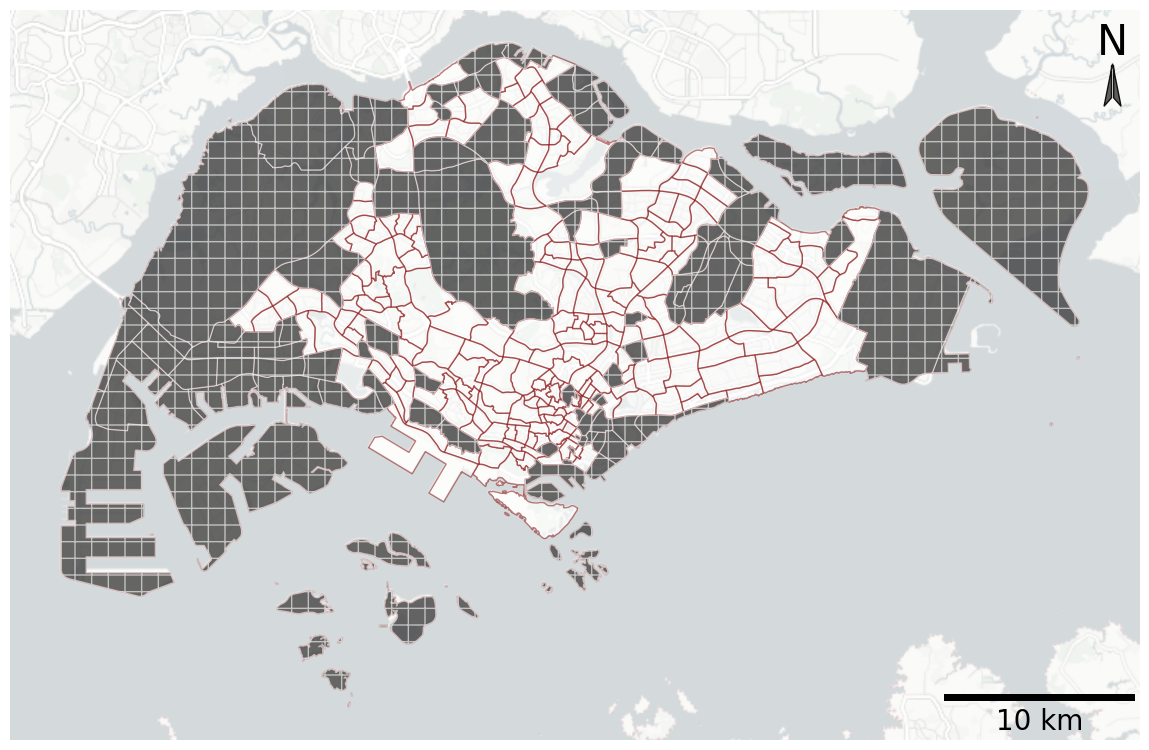

In [7]:
_, ax = plt.subplots(figsize=(12, 12))

# Subzones non-residential/missing areas
MISSKWDS = {
    "color": "black",
    "edgecolor": "white",
    "hatch": "+",
    "label": "Missing values",
}

htype[htype["resident_count"].isnull()].plot(
    column="resident_count",
    edgecolor="white",
    missing_kwds=MISSKWDS,
    alpha=0.6,
    ax=ax,
    zorder=2,
)

subzones.plot(
    color="white",
    edgecolor=EDGECOLOR,
    linewidth=1,
    alpha=0.5,
    rasterized=True,
    ax=ax,
    zorder=1,
)

cx.add_basemap(**BASEMAP_OPTS, ax=ax)
add_north_arrow(ax=ax, x=104.1, y=1.46, fontsize=30)
add_scalebar(ax=ax, fontsize=20)
plt.tight_layout()
plt.margins(0, 0)
plt.axis("off")

save_mpl_fig(os.path.join(SAVEPATH, "borders-neighbourhoods"))